# Team 5 — IT5006 Phase 3: Problem 1 on a time-ordered split
## Re-evaluating the fair-freight model as the Phase 2 feedback asked, and recording the search detail of both problems

The Phase 2 feedback asked us to use a **time-ordered split as the primary evaluation design for Problem 1** (tuning, model selection and performance reporting), to report **training scores** beside CV and test scores, and to report the **full search spaces, the decision-tree baseline settings and the voting weights evaluated**. Problem 2 was already evaluated this way in Phase 2. This notebook re-runs Problem 1 with the design Problem 2 uses and records the extra Problem 2 detail; the Phase 2 notebook is unchanged and remains the record of Phase 2, and Problem 2's results come from it.

What changes and what does not:

| | Phase 2 | Phase 3 (this notebook) |
|---|---|---|
| **Problem 1 test set** | random 20% of items, grouped by order | **latest 20% of items** by purchase time |
| **Problem 1 CV** (feature selection, tuning, model comparison) | 5-fold grouped CV | **5-fold forward-chaining CV** on the training period |
| **Selection rule** | simplest model within one fold sd of the best | simplest model within one sd of its **paired, fold-by-fold** shortfall against the best (Section 4) |
| **Feature groups** | paired rule on grouped CV: all four groups kept | same paired rule on **forward-chaining** folds (Section 2) |
| Model families, tuning grids, seed | | unchanged |
| **Problem 2** | time-ordered, forward-chaining CV | unchanged; Section 10 re-checks the selection with the paired rule and lists every search candidate |

The deployed application (`deployment/model_app/`) is rebuilt from the Problem 1 choices made here.

In [1]:
import os, sys, warnings, platform
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from IPython.display import display
import features as F, models as M, pipeline as P, plots as PL

pd.set_option("display.float_format", "{:,.3f}".format); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None); pd.set_option("display.html.use_mathjax", False)   # "R$" is currency, not maths
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | seed {F.RANDOM_STATE}")

python 3.14.3 | pandas 2.3.3 | numpy 2.4.2 | scikit-learn 1.8.0 | seed 42


## 1. Data and the time-ordered split

The item table is built exactly as in Phase 2 (112,650 order items). Training uses the **earliest 80% of items by purchase time**; the test set is the **latest 20%**. Unlike Problem 2, no gap is needed between them: freight is charged at checkout, so every training label is already known at the cut-off, whereas a delivery outcome is known only weeks later. All items of an order share one purchase time, so no order is split between training and test.

,Split,Items,Orders,Purchase dates,Mean freight (R$),Median freight per chargeable kg (R$)
0,Train (earliest 80%),90121,78814,2016-09-04 to 2018-05-24,19.534,10.024
1,Test (latest 20%),22529,19852,2018-05-24 to 2018-09-03,21.814,12.703


55.8% of test items are listings that also appear in training


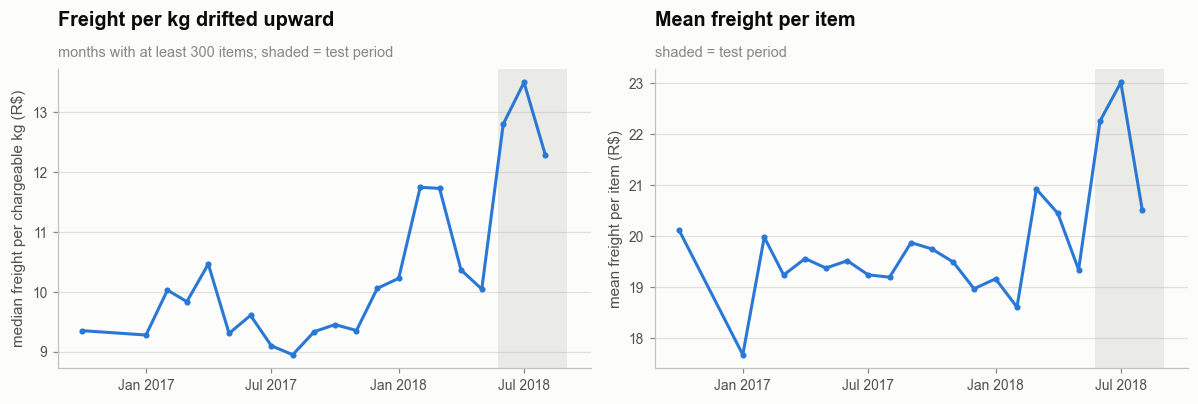

In [2]:
items = F.build_item_table()
tr, te = M.time_holdout(items, embargo_days=0)          # freight is known at checkout: no label delay
assert not set(tr.order_id) & set(te.order_id), "an order is in both train and test"
per_kg = lambda d: (d.freight_value / d.chargeable_kg.clip(lower=0.1)).median()
fmt = lambda s: f"{s.min():%Y-%m-%d} to {s.max():%Y-%m-%d}"
split = pd.DataFrame([{"Split": n, "Items": len(d), "Orders": d.order_id.nunique(), "Purchase dates": fmt(d.order_purchase_timestamp),
                       "Mean freight (R$)": d.freight_value.mean(), "Median freight per chargeable kg (R$)": per_kg(d)}
                      for n, d in [("Train (earliest 80%)", tr), ("Test (latest 20%)", te)]])
display(split)
print(f"{te.product_id.isin(set(tr.product_id)).mean():.1%} of test items are listings that also appear in training")
PL.freight_drift_chart(items, te.purchase_ts.min()); plt.show()

Freight drifted upward over time, so the test period is harder than the training period: **mean freight is R\$19.53 in training and R\$21.81 in the test period (+12%), and the median freight per chargeable kilogram rose from R\$10.02 to R\$12.70 (+27%). The test items are also less familiar: 44.2% of them are listings that never appear in training, against 22.2% on the Phase 2 random split**. A random split hides this, because it mixes every period into both sides.

**Forward-chaining CV.** The training period is cut into six consecutive blocks of equal size; fold *j* trains on blocks 1 to *j* and validates on block *j* + 1 (the same splitter as Problem 2, without the embargo). Every choice below (feature groups, hyper-parameters, model) is made on these folds; the test set is scored once, at the end.

In [3]:
cv = M.TimeForwardCV(5, embargo_days=0)
P.time_fold_table(tr, cv)

,Fold,Train dates,Train items,Validation dates,Validation items,Validation mean freight (R$),Orders in both
0,1,2016-09-04 to 2017-06-15,15021,2017-06-15 to 2017-09-25,15020,19.550,0
1,2,2016-09-04 to 2017-09-25,30040,2017-09-25 to 2017-12-01,15020,19.536,0
2,3,2016-09-04 to 2017-12-01,45061,2017-12-01 to 2018-02-03,15020,19.107,0
3,4,2016-09-04 to 2018-02-03,60081,2018-02-03 to 2018-03-30,15020,19.821,0
4,5,2016-09-04 to 2018-03-30,75101,2018-03-30 to 2018-05-24,15020,19.895,0


## 2. Feature-set selection on forward-chaining folds

As in Phase 2, a fixed forest is fitted on each nested feature set (a 40,000-item, order-grouped sample of the training period) and each added group is judged by its **paired gain**: the drop in MAE over the previous set, fold by fold, against the sd of that gain.

,Feature set,MAE (R$),RMSE (R$),R2 (R$),Gain (R$),Gain sd
0,0 Price only (reference),7.162,13.683,0.145,NaN,NaN
1,"1 Core (weight, volume, distance)",4.316,9.292,0.609,2.846,0.166
2,2 + category & states,3.940,8.888,0.642,0.376,0.068
3,3 + price & basket,3.771,8.574,0.667,0.169,0.046
4,4 + listing & timing,3.821,8.642,0.661,-0.050,0.108
5,5 + seller (target-encoded),3.796,8.645,0.661,0.024,0.034


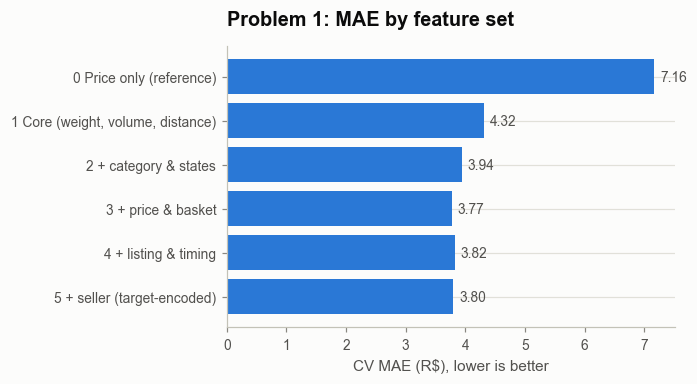

Modelling set: 3 + price & basket


In [4]:
ab = P.ablation_regression(tr, cv=cv)
display(ab); PL.ablation_chart_reg(ab); plt.show()
# retention rule: add groups while the paired gain exceeds its fold sd; seller identity (set 5) is excluded by design
FS_NAME = ab["Feature set"].iloc[0]
for _, row in ab.iloc[1:5].iterrows():
    if row["Gain (R$)"] <= row["Gain sd"]:
        break
    FS_NAME = row["Feature set"]
fs = F.FEATURE_SETS[FS_NAME]
cols = P.cols_for(fs)
print("Modelling set:", FS_NAME)

**Problem 1 feature groups on forward-chaining folds.** Weight, volume and distance cut MAE from R\$7.16 (price alone) to R\$4.32 (paired gain R\$2.85 ± 0.17), category and states bring it to R\$3.94 (+0.38 ± 0.07), and price and basket to R\$3.77 (+0.17 ± 0.05). **Listing details and purchase timing, kept in Phase 2, now raise the error** (−0.05 ± 0.11): on the random split they helped (+0.08 ± 0.01), but what they added held only within a period, so the rule drops them. Seller identity would add R\$0.02 ± 0.03 and is excluded by design in any case (a benchmark must not learn each seller's own pricing). The modelling set is **"3 + price & basket"**.

## 3. Tuning on forward-chaining folds

The same searches as Phase 2, scored by MAE on the log scale: a full grid for Ridge `alpha`, and a random search over 8 of the 36 forest settings on a 30,000-item order-grouped sample (100 trees during the search, 200 in the final fit). Every candidate is listed.

In [5]:
best, tune = P.tune_regression(tr, fs, cv=cv)
display(tune)
print("Ridge grid (every alpha):"); display(best["ridge_grid"])
print("Forest random search (every draw; search space: min_samples_leaf {2, 5, 10, 20} x max_features {0.2, 0.33, 0.5} x max_depth {None, 16, 24}):")
display(best["rf_search"])

,Problem,Model,Search,Best params,CV score,Scored by
0,1 Regression,Ridge,grid (6),{'m__alpha': 10},0.200,MAE (log)
1,1 Regression,RandomForest,random (8 of 36),"{'m__n_estimators': 100, 'm__min_samples_leaf': 2, 'm__max_features': 0.33, 'm__max_depth': 16}",0.171,MAE (log)


Ridge grid (every alpha):


,alpha,CV score,CV sd
0,10.000,0.200,0.047
1,100.000,0.200,0.047
2,1.000,0.200,0.047
3,0.100,0.200,0.047
4,0.010,0.200,0.047
5,"1,000.000",0.204,0.044


Forest random search (every draw; search space: min_samples_leaf {2, 5, 10, 20} x max_features {0.2, 0.33, 0.5} x max_depth {None, 16, 24}):


,n_estimators,min_samples_leaf,max_features,max_depth,CV score,CV sd
0,100,2,0.330,16,0.171,0.054
1,100,5,0.500,16,0.171,0.054
2,100,2,0.200,16,0.172,0.054
3,100,10,0.330,24,0.172,0.053
4,100,5,0.200,16,0.173,0.054
5,100,20,0.500,24,0.175,0.053
6,100,10,0.200,24,0.175,0.053
7,100,20,0.330,24,0.176,0.053


Forward-chaining tuning selects the same settings as the Phase 2 grouped search: Ridge `alpha=10` (every alpha up to 100 scores within 0.001 on the log scale) and a forest with `min_samples_leaf=2`, `max_features=0.33` and `max_depth=16` (log-scale MAE 0.171; the eight draws span 0.171 to 0.176, so the forest is not sensitive to these settings).

## 4. Cross-validation and model selection

The six models of Phase 2: the mean predictor (no skill), LinearRegression (linear baseline), Ridge, a decision tree (tree baseline: no depth limit, `min_samples_leaf=5`), the tuned forest (200 trees), and stacking (Ridge and the forest with 100 trees, combined by a Ridge meta-learner on 3-fold grouped out-of-fold predictions).

**Selection rule.** Phase 2 kept the simplest model whose mean CV score lay within one fold standard deviation of the best. On forward-chaining folds that sd mostly measures how freight differs between periods (every model has its worst fold in the same period), not how models differ, so the plain rule becomes too lenient. We therefore compare models **within each fold**: a model qualifies if its fold-by-fold shortfall against the best model is no larger than the sd of that shortfall, and the simplest qualifying model is chosen. This is the paired test the feature selection already uses.

In [6]:
models = P.final_reg_models(fs, best)
cv_tbl, folds = P.cv_regression(models, tr, fs, cv=cv, folds=True)
display(cv_tbl)
print("MAE (R$) of every model in each fold:"); display(folds)
FINAL, sel = P.pick_final_paired(folds, P.ORDER_A, higher=False)
display(sel)
plain = P.pick_final(cv_tbl, "MAE_rs mean", "MAE_rs sd", False, P.ORDER_A)
print(f"Final model (paired rule): {FINAL}   |   the plain fold-sd rule would pick: {plain}")

,Model,MAE_rs mean,RMSE_rs mean,R2_rs mean,R2_log mean,MAE_rs sd,RMSE_rs sd,R2_rs sd
0,Mean predictor (dummy),7.484,15.229,-0.031,-0.002,0.745,1.434,0.006
1,Linear: LinearRegression,4.586,10.578,0.505,0.576,0.779,1.552,0.053
2,Linear: Ridge,4.585,10.590,0.504,0.576,0.777,1.549,0.053
3,Tree: DecisionTree (baseline),4.163,9.081,0.635,0.539,0.845,1.545,0.061
4,Tree: RandomForest,3.709,8.453,0.684,0.643,0.875,1.638,0.063
5,Ensemble: Stacking (Ridge + RF),3.706,8.418,0.687,0.644,0.869,1.632,0.063


MAE (R$) of every model in each fold:


,Mean predictor (dummy),Linear: LinearRegression,Linear: Ridge,Tree: DecisionTree (baseline),Tree: RandomForest,Ensemble: Stacking (Ridge + RF)
Fold,,,,,,
1,7.108,4.378,4.380,3.891,3.381,3.409
2,7.241,4.250,4.253,3.830,3.402,3.381
3,6.920,3.900,3.896,3.401,2.907,2.905
4,7.368,4.478,4.480,4.086,3.657,3.651
5,8.784,5.922,5.918,5.606,5.197,5.182


,Model,Mean,Shortfall vs best,Shortfall sd,Within one sd
0,Mean predictor (dummy),7.484,3.778,0.161,False
1,Linear: LinearRegression,4.586,0.880,0.105,False
2,Linear: Ridge,4.585,0.880,0.105,False
3,Tree: DecisionTree (baseline),4.163,0.457,0.031,False
4,Tree: RandomForest,3.709,0.003,0.019,True
5,Ensemble: Stacking (Ridge + RF),3.706,0.000,0.000,True


Final model (paired rule): Tree: RandomForest   |   the plain fold-sd rule would pick: Tree: DecisionTree (baseline)


Stacking has the lowest mean CV MAE (R\$3.71), but the forest is level with it fold by fold: its shortfall is R\$0.003 ± 0.019, within one sd, so **the simpler forest is selected**. Every other model is clearly behind: the tree by R\$0.46 ± 0.03 and the linear models by R\$0.88 ± 0.11 per fold. The fold sd of each model (about R\$0.85) comes from fold 5 (30 March to 24 May 2018), where every model does worst; the plain Phase 2 rule would therefore have kept the decision tree, which is worse than the forest in every fold.

## 5. Test set: training, cross-validation and test scores

Every model is refitted on the whole training period and scored once on the latest 20% of items. Training scores are the models' errors on their own training rows: training much better than CV means over-fitting, all three poor means under-fitting.

In [7]:
fit = P.fit_all(models, tr, "reg_target", fs)
test_tbl = P.test_regression(fit, te, fs)
tvt = P.train_val_test_regression(fit, tr, fs, cv_tbl, test_tbl)
tvt = tvt.assign(**{"Test RMSE": test_tbl.RMSE_rs.values, "Test MAE % of mean freight": tvt["Test MAE"] / te.freight_value.mean() * 100})
tvt

,Model,Train MAE,CV MAE,Test MAE,CV - train MAE,Train R2,CV R2,Test R2,Test RMSE,Test MAE % of mean freight
0,Mean predictor (dummy),7.317,7.484,9.614,0.167,-0.034,-0.031,-0.072,19.478,44.072
1,Linear: LinearRegression,4.416,4.586,6.127,0.170,0.524,0.505,0.428,14.234,28.087
2,Linear: Ridge,4.416,4.585,6.123,0.169,0.524,0.504,0.427,14.243,28.068
3,Tree: DecisionTree (baseline),2.184,4.163,5.686,1.978,0.863,0.635,0.589,12.062,26.067
4,Tree: RandomForest,2.530,3.709,5.398,1.178,0.855,0.684,0.591,12.032,24.746
5,Ensemble: Stacking (Ridge + RF),2.510,3.706,5.321,1.196,0.863,0.687,0.607,11.787,24.394


On the latest 20% of items the forest's MAE is **R\$5.40** (R² 0.591), **24.7% of mean test freight**. It beats the mean predictor (R\$9.61), the linear baseline (R\$6.13) and the tree (R\$5.69), but it **misses the 20% success target** set in Phase 2. Stacking scores R\$5.32, a difference the CV folds showed to be noise. The training scores tell the same story as in Phase 2: the linear models score alike on their training rows and in CV (R\$4.42 and R\$4.59), an under-fit; the single tree over-fits (R\$2.18 in training against R\$4.16 in CV); the forest fits its training rows closely (R\$2.53) but generalises best. The step from CV (R\$3.71) to test (R\$5.40) is larger than between any two folds, because the test period follows a further rise in freight.

## 6. How optimistic was the random split?

The same six models, fitted on the Phase 2 random split (80/20, grouped by order) and scored on its random test set, against the time-ordered test set. A second check scores the time-ordered models only on the test items whose listing never appears in training.

,Model,Random MAE,Time-ordered MAE,"Time-ordered, unseen listings MAE"
0,Mean predictor (dummy),7.742,9.614,10.315
1,Linear: LinearRegression,4.736,6.127,6.560
2,Linear: Ridge,4.736,6.123,6.553
3,Tree: DecisionTree (baseline),4.366,5.686,6.155
4,Tree: RandomForest,3.646,5.398,5.755
5,Ensemble: Stacking (Ridge + RF),3.645,5.321,5.664


unseen listings: 9,947 of 22,529 test items (44.2%); their mean freight R$22.51


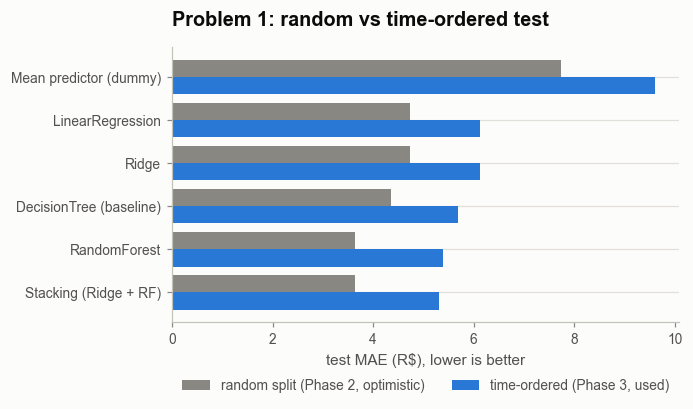

In [8]:
strat = pd.qcut(items.reg_target.rank(method="first"), 5, labels=False)
tr_r, te_r = M.holdout_split(items, strat)
rand = P.test_regression(P.fit_all(models, tr_r, "reg_target", fs), te_r, fs)
new = ~te.product_id.isin(set(tr.product_id))
unseen = P.test_regression(fit, te[new], fs)
comp = pd.DataFrame({"Model": rand.Model, "Random MAE": rand.MAE_rs, "Time-ordered MAE": test_tbl.MAE_rs.values,
                     "Time-ordered, unseen listings MAE": unseen.MAE_rs.values})
display(comp)
print(f"unseen listings: {new.sum():,} of {len(te):,} test items ({new.mean():.1%}); their mean freight R${te[new].freight_value.mean():.2f}")
PL.split_chart_reg(comp); plt.show()

The random split was optimistic. On it the same forest scores R\$3.65, against R\$5.40 on later items. Every model does worse on the time-ordered test, from +24% (mean predictor) to +48% (forest), but the ranking of models is unchanged: what changes is the error the analyst should expect. On test items whose listing never appears in training the forest's MAE is R\$5.76 (25.6% of their mean freight of R\$22.51).

## 7. The final model: errors and importance

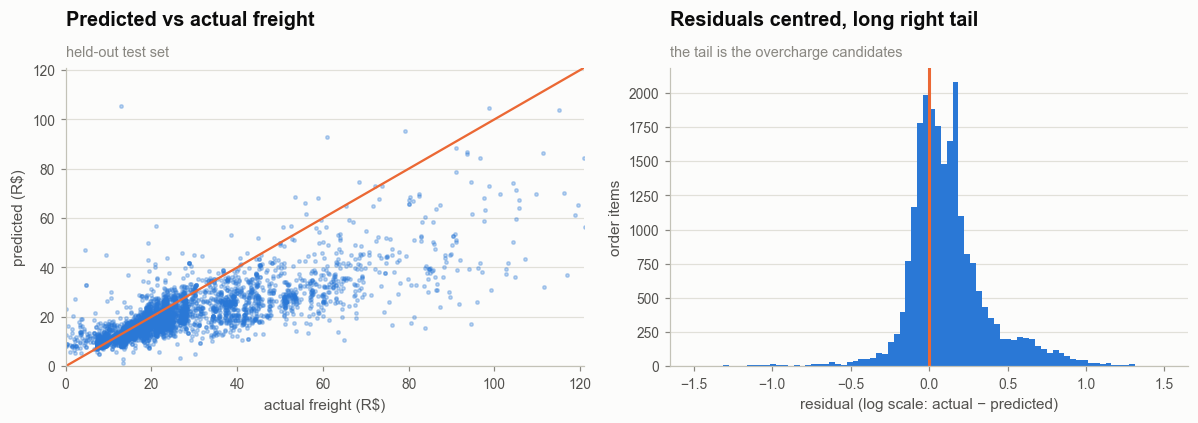

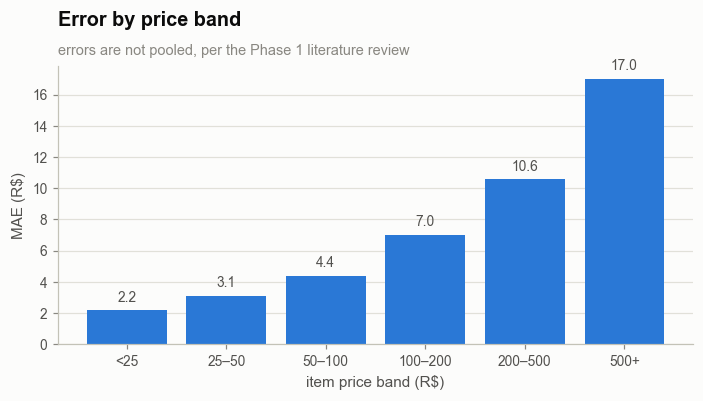

,MAE,MAE % of mean freight,n
band,,,
<25,2.161,16.117,2686
25–50,3.076,19.248,5288
50–100,4.398,22.647,6156
100–200,7.012,27.426,5798
200–500,10.558,29.713,1924
500+,16.993,33.066,677


In [9]:
pred = fit[FINAL].predict(te[cols])
PL.pred_vs_actual(te.reg_target, pred); plt.show()
band = PL.error_by_price_band(te, pred)
plt.show(); band

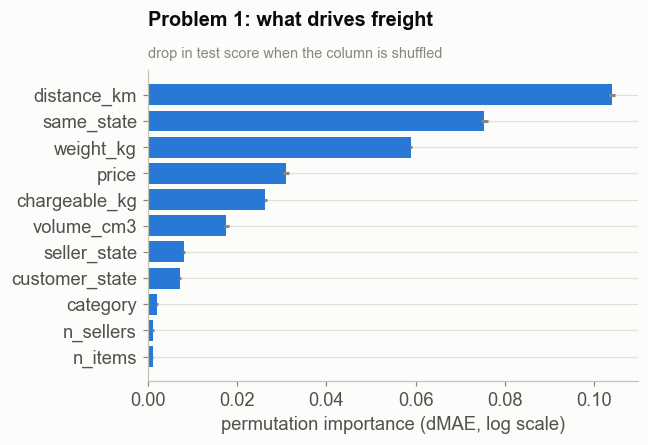

Stacking meta-learner (for comparison): log-freight = -0.067 + -0.006 x Ridge + 1.030 x forest


,feature,importance,sd
0,distance_km,0.104,0.001
1,same_state,0.075,0.001
2,weight_kg,0.059,0.000
3,price,0.031,0.001
4,chargeable_kg,0.026,0.000
5,volume_cm3,0.018,0.000
6,seller_state,0.008,0.000
7,customer_state,0.007,0.000


In [10]:
imp = P.perm_importance(fit[FINAL], te, fs, "reg_target")
PL.importance_bar(imp, "Problem 1: what drives freight", unit="(dMAE, log scale)"); plt.show()
meta = fit["Ensemble: Stacking (Ridge + RF)"].final_estimator_
print(f"Stacking meta-learner (for comparison): log-freight = {meta.intercept_:.3f} + {meta.coef_[0]:.3f} x Ridge + {meta.coef_[1]:.3f} x forest")
imp.head(8)

Distance matters most: shuffling it raises the forest's log-scale test MAE by 0.104. The same-state flag (0.075), weight (0.059) and price (0.031) follow, while the states add little once distance and the same-state flag are known. The same-state flag ranks second even with distance in the model: freight jumps when a parcel crosses a state border rather than rising smoothly with kilometres. The stacking meta-learner puts almost all its weight on the forest (1.03, against −0.01 on Ridge), which is why stacking cannot improve on it. Errors grow with price, from R\$2.16 for items under R\$25 (16.1% of their mean freight) to R\$16.99 above R\$500 (33.1%), so a single tolerance would be too tight for expensive items.

## 8. A transparent tariff on the time-ordered split

The plain least-squares tariff of Phase 2 (freight = base + R\$ per chargeable kg + R\$ per 100 km + a same-state term), fitted on the training period and scored on the test period.

In [11]:
tariff = P.implied_tariff(tr, te)
tariff

,Term,Value
0,Base charge (R$),9.614
1,Per chargeable kg (R$),1.846
2,Per 100 km (R$),0.811
3,Same-state shipment (R$),-3.985
4,Test MAE of this tariff (R$),6.221


## 9. The unusual-freight audit on the latest period

The audit now runs as it would in use: models trained on the past score the charges of a later period. Items whose log-scale residual is in the top 5% of the test period are flagged, by the final model and, as a second opinion, by Ridge. The cut-off is relative to the period audited, so the upward drift in freight shifts every residual but does not by itself fill the list.

mean log residual in the test period: +0.116 (final model), +0.125 (Ridge)


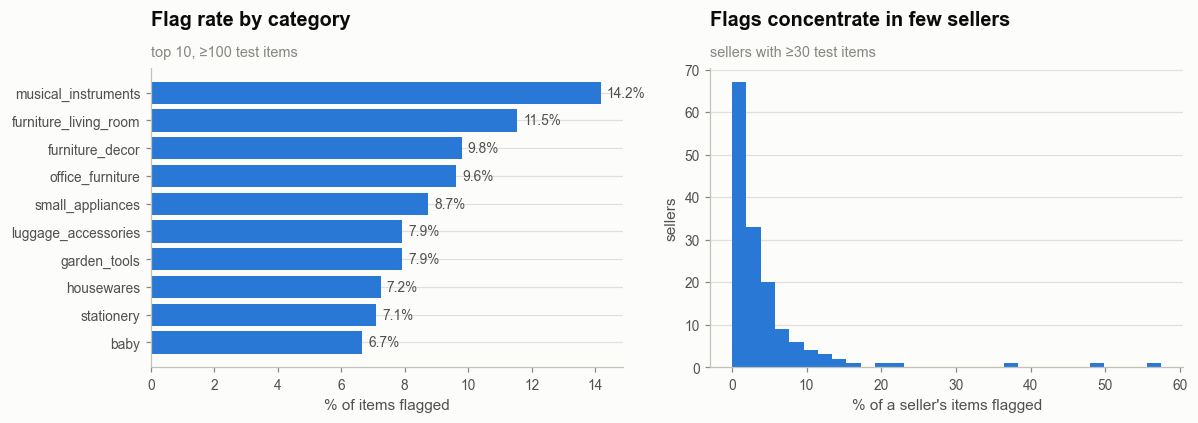

,metric,value
0,items flagged,"1,128.000"
1,mean actual freight R$,61.179
2,mean expected freight R$,25.871
3,mean excess R$,35.308
4,excess as % of all test freight,8.104
5,flagged items from top 5% of sellers (by flag count),54.699
6,flagged by both forest and Ridge (%),66.223
7,agreement of forest and Ridge flags (Jaccard),0.495


In [12]:
flagged, stab = P.flag_overcharge(te, pred, fit["Linear: Ridge"].predict(te[cols]), q=0.95)
print(f"mean log residual in the test period: {flagged.resid_primary.mean():+.3f} (final model), {flagged.resid_check.mean():+.3f} (Ridge)")
sell = PL.overcharge_charts(flagged); plt.show()
P.audit_summary(flagged, stab, names=("forest" if FINAL == "Tree: RandomForest" else "stacked model", "Ridge"))

In [13]:
conc, flag_band = P.audit_concentration(flagged)
display(conc, flag_band)
print("Sellers with the highest flag rates (at least 30 test items):")
sell.sort_values("rate", ascending=False).head(10).reset_index()

,metric,value
0,median markup (actual / expected),2.259
1,top 5% sellers by flags: % of flags,54.699
2,top 5% sellers by flags: % of items,27.174
3,top 5% sellers by items: % of items,43.482
4,top 5% sellers by items: % of flags,32.092


,flag_rate,n
price,,
<50,0.023,7917
50–100,0.046,6169
100–200,0.074,5826
200–500,0.088,1935
500+,0.095,682


Sellers with the highest flag rates (at least 30 test items):


,seller_id,n,rate,excess
0,0dd184061fb0eaa7ca37932c68ab91c5,40,0.575,731.553
1,79ebd9a61bac3eaf882805ed4ecfa12a,41,0.488,771.975
2,77530e9772f57a62c906e1c21538ab82,55,0.382,678.535
3,cc5a78bbad32776dc4e3af205218368c,35,0.229,451.498
4,1f50f920176fa81dab994f9023523100,173,0.197,"1,657.847"
5,3d871de0142ce09b7081e2b9d1733cb1,94,0.160,948.771
6,17a053fcb14bd219540cbde0df490be0,33,0.152,777.446
7,7681ef142fd2c19048da7430856b5588,34,0.147,238.206
8,c33847515fa6305ce6feb1e818569f13,124,0.129,"1,182.993"
9,6061155addc1e54b4cfb51c1c2a32ad8,33,0.121,268.006


The audit flags 1,128 of the 22,529 test items (5.0%). They were charged R\$61.18 on average against a fair freight of R\$25.87 (median markup 2.26×), and their excess equals 8.1% of all test freight, an upper bound on what audits could recover, since fragile goods, data errors or cost recovery also produce high charges. Ridge confirms 66% of the flags, and those are reviewed first. Flags concentrate: the 5% of sellers with the most flags hold 55% of them but ship 27% of the items, while the 5% largest sellers ship 43% of the items and hold 32% of the flags, so audits should go to mid-sized sellers with high flag rates. Under one cut-off the flag rate rises from 2.3% for items under R\$50 to 9.5% above R\$500; a cut-off within each price band avoids that. Both models see freight above its training level in the test period (mean log residual +0.12 and +0.13), but the cut-off is the top 5% of the period audited, so the drift shifts every residual rather than filling the list.

## 10. Problem 2: the selection rule and the full search record

Problem 2 already uses a time-ordered test window (orders from 26 May 2018, after a 30-day gap) and forward-chaining CV (Phase 2 notebook, Sections 4 to 8). Two things are added here: every candidate of its three searches, and a check that the paired selection rule of Section 4 keeps the same final model. The feature set is the one Phase 2's forward selection kept: promise, route, and order value and freight.

In [14]:
orders = F.build_order_table()
tr_b, te_b = M.time_holdout(orders)
fs_b = P.merge_sets(P.merge_sets(F.LATE_BASE, F.LATE_GROUPS["route (distance, states)"]), F.LATE_GROUPS["order value & freight"])
best_b, tune_b = P.tune_classification(tr_b, fs_b)
display(tune_b)
print("L2 logistic grid (every candidate; PR-AUC lift):"); display(best_b["logit_grid"])
print("Forest random search, 20 of 240 settings: min_samples_leaf {10, 20, 50, 100, 200} x max_features {sqrt, 0.2, 0.3, 0.5}"
      " x max_depth {6, 10, 16, None} x class_weight {None, balanced, balanced_subsample}:")
display(best_b["rf_search"])
print("Soft-voting weights evaluated (weight on the logistic model; the forest gets the rest):"); display(best_b["vote_grid"])

,Problem,Model,Search,Best params,CV score,Scored by
0,2 is_late,Logistic (L2),grid (8),"{'m__C': 0.1, 'm__class_weight': None}",2.028,PR-AUC lift
1,2 is_late,RandomForest,random (20 of 240),"{'m__n_estimators': 100, 'm__min_samples_leaf': 100, 'm__max_features': 'sqrt', 'm__max_depth': None, 'm__class_weight': 'balanced'}",1.860,PR-AUC lift
2,2 is_late,Voting (Logit + RF),grid (3),{'w_logit': 0.75},1.991,PR-AUC lift


L2 logistic grid (every candidate; PR-AUC lift):


,C,class_weight,CV score,CV sd
0,0.100,None,2.028,0.316
1,1.000,None,2.025,0.306
2,0.010,balanced,2.016,0.318
3,10.000,None,2.012,0.307
4,0.010,None,2.011,0.370
5,0.100,balanced,2.007,0.294
6,10.000,balanced,2.005,0.291
7,1.000,balanced,2.004,0.291


Forest random search, 20 of 240 settings: min_samples_leaf {10, 20, 50, 100, 200} x max_features {sqrt, 0.2, 0.3, 0.5} x max_depth {6, 10, 16, None} x class_weight {None, balanced, balanced_subsample}:


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,CV score,CV sd
0,100,100,sqrt,NaN,balanced,1.860,0.309
1,100,100,0.300,10.000,balanced,1.856,0.317
2,100,20,0.200,6.000,None,1.850,0.342
3,100,10,0.200,10.000,balanced_subsample,1.846,0.338
4,100,200,0.300,10.000,balanced,1.845,0.298
5,100,10,0.200,16.000,None,1.845,0.296
6,100,20,0.200,6.000,balanced,1.845,0.326
7,100,200,sqrt,10.000,balanced,1.841,0.289
8,100,20,0.200,16.000,balanced_subsample,1.838,0.304
9,100,200,sqrt,10.000,None,1.829,0.287


Soft-voting weights evaluated (weight on the logistic model; the forest gets the rest):


,CV score,CV sd,w_logit
0,1.991,0.336,0.750
1,1.954,0.334,0.500
2,1.914,0.325,0.250


In [15]:
models_b = P.final_clf_models(fs_b, best_b)
folds_b = P.fold_scores_classification(models_b, tr_b, fs_b)
print("Lift of every model in each forward-chaining fold:"); display(folds_b)
FINAL_B, sel_b = P.pick_final_paired(folds_b, P.ORDER_B, higher=True)
display(sel_b)
print(f"Final model (paired rule): {FINAL_B}")

Lift of every model in each forward-chaining fold:


,Prior predictor (dummy),Linear: LogisticRegression (plain),Linear: Logistic (L2),Tree: DecisionTree (baseline),Tree: RandomForest,Ensemble: Voting (Logit + RF)
Fold,,,,,,
1,1.000,2.043,1.913,1.322,1.816,1.938
2,1.000,1.733,1.737,1.123,1.668,1.757
3,1.000,1.607,1.687,1.081,1.480,1.558
4,1.000,2.259,2.334,1.430,2.154,2.303
5,1.000,2.409,2.466,1.474,2.290,2.445


,Model,Mean,Shortfall vs best,Shortfall sd,Within one sd
0,Prior predictor (dummy),1.000,1.028,0.353,False
1,Linear: LogisticRegression (plain),2.010,0.018,0.087,True
2,Linear: Logistic (L2),2.028,0.000,0.000,True
3,Tree: DecisionTree (baseline),1.286,0.741,0.191,False
4,Tree: RandomForest,1.882,0.146,0.059,False
5,Ensemble: Voting (Logit + RF),2.000,0.027,0.062,True


Final model (paired rule): Linear: LogisticRegression (plain)


**Problem 2 is unchanged.** The searches reproduce Phase 2: logistic `C=0.1` without class weights (lift 2.028); a forest with leaf size 100, square-root features, no depth limit and balanced weights (1.860); and a voting weight of 0.75 on the logistic model (1.991, against 1.954 for 0.5 and 1.914 for 0.25). Under the paired rule plain logistic regression qualifies (shortfall 0.018 ± 0.087 against the L2 model, the best by mean lift), so it remains the final model, as under the Phase 2 rule.

**Baseline settings (not tuned).** Decision tree for Problem 1: no depth limit, `min_samples_leaf=5`; for Problem 2: no depth limit, `min_samples_leaf=20`, no class weight. Linear baselines: LinearRegression and LogisticRegression without a penalty (up to 2,000 iterations). No-skill references: the training mean and the training late rate.

In [16]:
pd.DataFrame([{"Problem": p, "Model": n, "Settings": str({k: v for k, v in m.named_steps["m"].get_params().items()
                                                          if k in ("max_depth", "min_samples_leaf", "class_weight", "penalty", "max_iter", "strategy")})}
              for p, ms in [("1", models), ("2", models_b)] for n, m in ms.items()
              if n.startswith(("Mean", "Prior", "Linear: LinearRegression", "Linear: LogisticRegression", "Tree: DecisionTree"))])

,Problem,Model,Settings
0,1,Mean predictor (dummy),{'strategy': 'mean'}
1,1,Linear: LinearRegression,{}
2,1,Tree: DecisionTree (baseline),"{'max_depth': None, 'min_samples_leaf': 5}"
3,2,Prior predictor (dummy),{'strategy': 'prior'}
4,2,Linear: LogisticRegression (plain),"{'class_weight': None, 'max_iter': 2000, 'penalty': None}"
5,2,Tree: DecisionTree (baseline),"{'class_weight': None, 'max_depth': None, 'min_samples_leaf': 20}"


## 11. What changed from Phase 2

| | Phase 2 | Phase 3 |
|---|---|---|
| **Problem 1 test set** | random 20% of items, grouped by order | latest 20% of items (from 24 May 2018) |
| **Feature groups** | four, including listing details and purchase timing | three: listing details and timing did not help on later periods |
| **Selection rule** | within one fold sd of the best | within one sd of the paired, fold-by-fold shortfall |
| **Final model** | random forest | random forest (same settings, 200 trees); stacking is level with it |
| **Test MAE** | R\$3.55 (17.8% of mean freight) | R\$5.40 (24.7%) |
| **20% target** | met | missed: freight per kilogram rose 27% between the periods |
| **Audit** | 1,127 never-seen listings | 1,128 items of the latest period; Ridge agrees on 66% |
| **Problem 2** | plain logistic regression | unchanged; the paired rule keeps it |

**What this means for the analyst.** The benchmark still ranks charges well within a period, which is what the audit needs, but its level drifts with the tariff: errors on new charges are about a quarter of mean freight, and the model should be retrained monthly on recent items. The deployed application uses the forest trained here and audits the latest 20% of items.